In [77]:
import hashlib
import os
import platform
import uuid
import sys

# 修改为自己的学号
STUDENT_ID = 20244080314  

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] exp03
[学号] 20244080314
[机器指纹] 71540edf6c2a7b53
[RUN_ID] 20244080314-71540edf6c2a7b53


任务一：围绕半圆定律 (Wigner 矩阵)

1. wigner_density (x) 半圆密度函数

In [78]:
import numpy as np
import matplotlib.pyplot as plt

# 半圆定律密度函数
def wigner_density(x):
    if -2 <= x <= 2:
        return float((1 / (2 * np.pi)) * np.sqrt(4 - x**2))
    else:
        return 0.0

wigner_density(x) 函数说明：该函数实现Wigner半圆定律的密度函数。
当 $|x|\le 2$ 时，返回密度值 $f(x)=\frac{1}{2\pi}\sqrt{4-x^2}$；$|x|>2$ 时返回0。
使用np.sqrt计算平方根，兼容普通数值与numpy数组输入。


2. generate_wigner (n) 生成 Wigner 对称随机矩阵

In [79]:
# 生成n阶Wigner对称随机矩阵
def generate_wigner(n):
    if not isinstance(n, int) or n <= 0:
        raise ValueError("n 必须是正整数")
    std = np.sqrt(1 / n)
    Z = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            Z[i, j] = np.random.normal(0, std)
            Z[j, i] = Z[i, j]
    return Z

generate_wigner(n) 函数说明：
用于生成n阶Wigner对称随机矩阵。
- 校验输入：n不是正整数时抛出ValueError；
- 上三角与对角线位置独立采样均值0、方差$1/n$的正态分布；
- 令 $Z_{ji}=Z_{ij}$，保证矩阵对称，符合Wigner矩阵定义。


3. get_spectrum (matrix) 计算并排序特征值

In [80]:
# 获取矩阵全部特征值，按从小到大排序
def get_spectrum(matrix):
    eigenvalues = np.linalg.eigvalsh(matrix)
    return np.sort(eigenvalues)

get_spectrum(matrix) 函数说明：
输入对称矩阵，使用np.linalg.eigvalsh（专门针对对称矩阵，计算更快、数值更稳定）求解特征值，最后返回按非递减顺序排序的特征值数组。

4. 绘图，4 张子图对比 n=100,200,500,1000

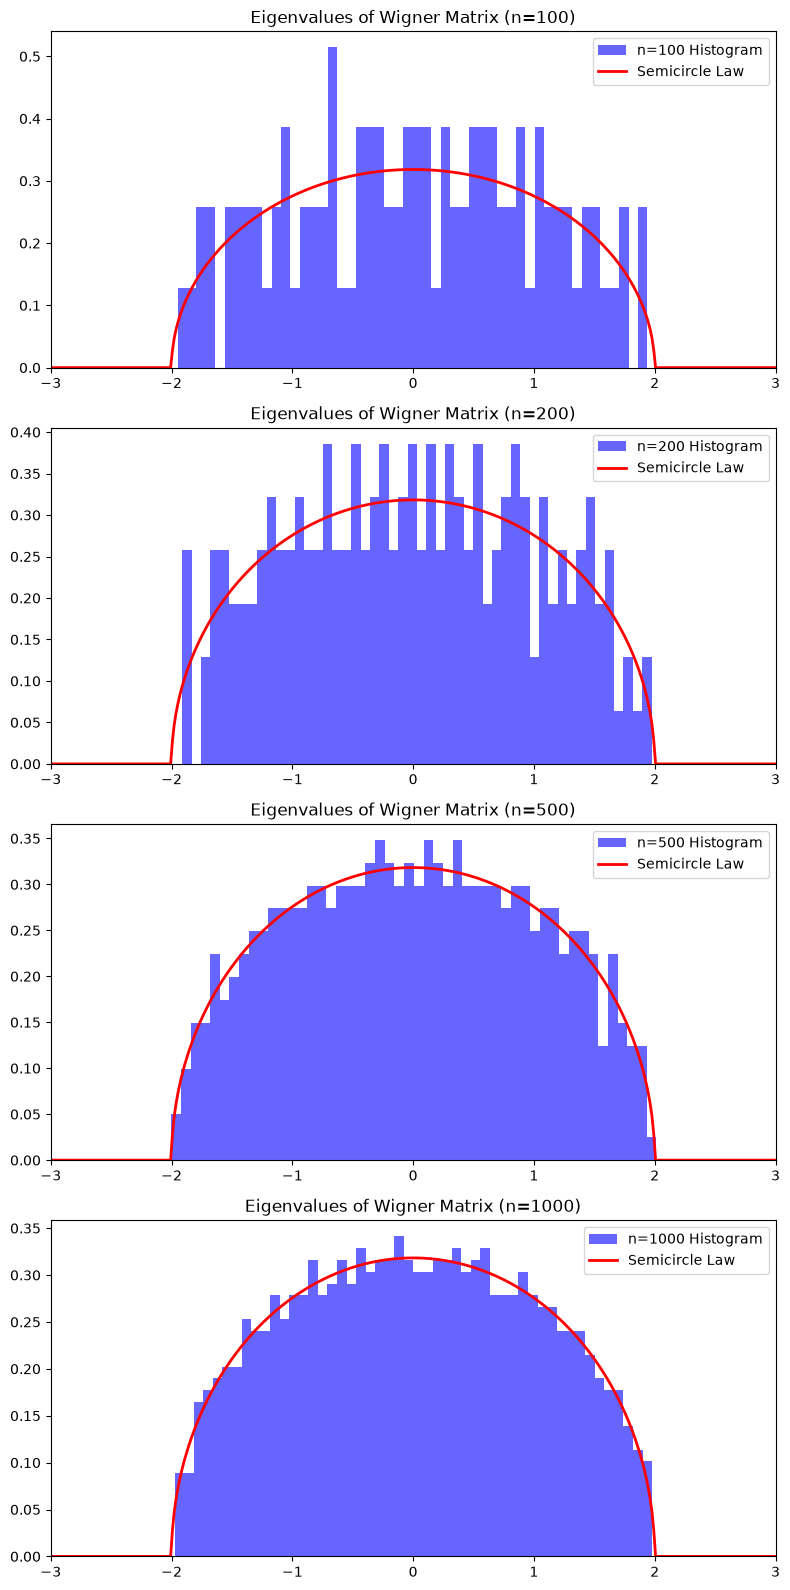

In [81]:
# 绘图：4个子图纵向排列
n_values = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 16))

x_vals = np.linspace(-3, 3, 400)
y_vals = [wigner_density(x) for x in x_vals]

for i, n in enumerate(n_values):
    Z = generate_wigner(n)
    eigvals = get_spectrum(Z)
    
    ax = axes[i]
    ax.hist(eigvals, bins=50, density=True, color='blue', alpha=0.6, label=f'n={n} Histogram')
    ax.plot(x_vals, y_vals, color='red', linewidth=2, label='Semicircle Law')
    
    ax.set_title(f"Eigenvalues of Wigner Matrix (n={n})")
    ax.set_xlim(-3, 3)
    ax.legend()

plt.tight_layout()
plt.show()


结果说明：
蓝色柱状图为Wigner矩阵特征值的标准化直方图，红色曲线为半圆定律的理论密度曲线。
- $n=100$：矩阵阶数较小，特征值分布随机性强，直方图起伏明显，与理论曲线偏差较大；
- $n=200$：波动有所减弱，分布开始向半圆曲线靠拢；
- $n=500$：直方图明显平滑，和理论半圆曲线拟合效果良好；
- $n=1000$：分布进一步收敛，直方图几乎与理论曲线重合。

由图像可以看出：当矩阵阶数 n 达到 500 左右时，特征值分布能够较好地满足半圆定律。

任务二：Conway 的生命游戏

1. 编写 is_valid_board(board) 校验棋盘有效性

In [82]:
import numpy as np
import matplotlib.pyplot as plt

# 验证棋盘是否合法
def is_valid_board(board):
    # 判断是否为numpy数组
    if not isinstance(board, np.ndarray):
        return False
    # 判断是否二维数组
    if board.ndim != 2:
        return False
    # 判断所有元素只能是0或者1
    if not np.all((board == 0) | (board == 1)):
        return False
    return True


函数 is_valid_board(board)：该函数用于检验生命游戏棋盘的合法性。
判断逻辑：
1. 判断输入是否为 NumPy ndarray数组；
2. 判断数组是否为二维；
3. 判断数组所有元素只能是0或1。

全部条件满足返回True，任意条件不满足返回False。

2. 编写 gol_step(board) 棋盘演化一步

In [83]:
# 演化一步生命游戏
def gol_step(board):
    # 校验棋盘，无效抛出异常
    if not is_valid_board(board):
        raise ValueError("输入的棋盘无效")

    m, n = board.shape
    neighbor_sum = np.zeros((m, n))

    # 八邻域累加，np.roll实现环绕边界
    for i in [-1, 0, 1]:
        for j in [-1, 0, 1]:
            if i == 0 and j == 0:
                continue
            neighbor_sum += np.roll(np.roll(board, i, axis=0), j, axis=1)

    # 生命游戏规则
    # 活细胞：邻居2/3存活；死细胞：邻居3复活，其余死亡
    new_board = ((neighbor_sum == 3) | ((board == 1) & (neighbor_sum == 2))).astype(int)
    return new_board


函数 gol_step(board)：实现棋盘的一步演化，返回和输入尺寸相同的新numpy数组。
1. 首先调用is_valid_board()校验棋盘，棋盘非法抛出ValueError("输入的棋盘无效")；
2. 使用双重循环遍历8个邻域方向，借助np.roll()实现题目要求的环绕边界，统计每个细胞八邻域活细胞数量；
3. 严格按照康威生命游戏规则：
    - 活细胞：邻居数为2或3时存活，否则死亡；
    - 死细胞：恰好拥有3个活邻居时复活，其余保持死亡。
    
所有细胞的邻居计数均使用原始棋盘数据，保证同步更新。

3. 编写 draw_gol_board(board) 绘制棋盘

In [84]:
# 绘制生命游戏棋盘
def draw_gol_board(board):
    fig, ax = plt.subplots(figsize=(6, 6))
    # 获取颜色映射，0白色，1黑色
    cmap = plt.get_cmap('Greys')
    ax.imshow(board, cmap=cmap, vmin=0, vmax=1)

    # 隐藏刻度
    ax.set_xticks([])
    ax.set_yticks([])
    # 隐藏边框
    for spine in ax.spines.values():
        spine.set_visible(False)

    plt.show()


函数 draw_gol_board(board)：实现棋盘可视化绘图。
1. 通过plt.get_cmap('Greys')获取颜色映射：死细胞0为白色，活细胞1为黑色；
2. 使用imshow绘制棋盘，设置vmin=0, vmax=1固定颜色范围；
3. 清空x、y轴刻度，隐藏全部坐标轴边框，只展示细胞方格图像，不输出坐标轴标签与网格。

4. 测试运行代码

原始状态：


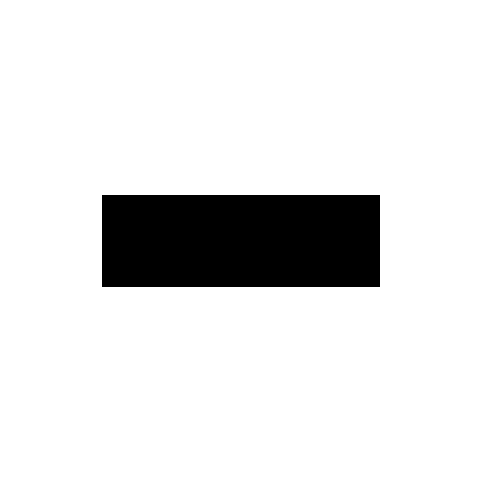

演化一步之后：


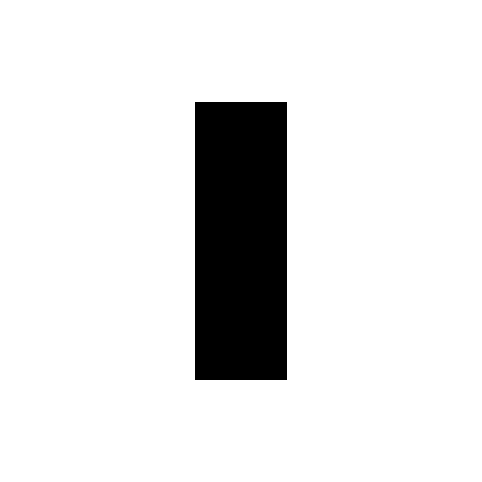

In [85]:
# 测试 
board_test = np.zeros((5, 5), dtype=int)
board_test[2, 1:4] = 1   # 横向三个活细胞

print("原始状态：")
draw_gol_board(board_test)

print("演化一步之后：")
next_board = gol_step(board_test)
draw_gol_board(next_board)


结果说明：构造5×5的零矩阵作为测试棋盘，在第2行放置横向连续3个活细胞，该图案为生命游戏里的振荡器（闪烁器）。

- 原始状态：水平方向3个连续活细胞；
- 调用gol_step()完成一步演化，再调用绘图函数查看结果；
- 演化后细胞变为竖直方向3个活细胞，符合振荡器的演化特征。

代码采用np.roll实现环绕边界，棋盘边界上的细胞邻居会从棋盘的对侧获取，满足题目边界条件。


任务三：使⽤ pandas DataFrame

1. 读取 csv，查看数据集基本信息

In [86]:
import pandas as pd

# CSV第一行为列标题
df = pd.read_csv("iris.csv", index_col=0)
df.columns = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]

# 该csv无species列，按iris标准行顺序补充花卉种类
df["species"] = ["setosa"] * 50 + ["versicolor"] * 50 + ["virginica"] * 50

print("数据集基本信息：")
print("数据点个数(行数):", df.shape[0])
print("列名:", df.columns.tolist())
print("各列数据类型:\n", df.dtypes)
print("花卉种类:", df["species"].unique().tolist())
print("花卉种类数量:", df["species"].nunique())


数据集基本信息：
数据点个数(行数): 150
列名: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)', 'species']
各列数据类型:
 sepal length (cm)    float64
sepal width (cm)     float64
petal length (cm)    float64
petal width (cm)     float64
species                  str
dtype: object
花卉种类: ['setosa', 'versicolor', 'virginica']
花卉种类数量: 3


数据集基本信息说明：
该鸢尾花数据集一共有 **150 个数据点**。
数据集包含5列：4项测量特征sepal length (cm)、sepal width (cm)、petal length (cm)、petal width (cm)，以及类别列species。
- 4个测量列为浮点型float64，用于存放测量数值；
- species列为字符串类型str，存储花卉类别。

数据集共包含3种鸢尾花：setosa、versicolor、virginica。


2. 修改指定两行并检查

In [87]:
meas = ["sepal length (cm)", "sepal width (cm)", "petal length (cm)", "petal width (cm)"]

# 索引34：原文件第35行
df.loc[34, meas] = [4.9, 3.1, 1.5, 0.2]
df.loc[34, "species"] = "setosa"

# 索引37：原文件第38行
df.loc[37, meas] = [4.9, 3.6, 1.4, 0.1]
df.loc[37, "species"] = "setosa"

print("\n校验修改后的两行：")
print("修改后 索引34:\n", df.loc[34])
print("修改后 索引37:\n", df.loc[37])



校验修改后的两行：
修改后 索引34:
 sepal length (cm)       4.9
sepal width (cm)        3.1
petal length (cm)       1.5
petal width (cm)        0.2
species              setosa
Name: 34, dtype: object
修改后 索引37:
 sepal length (cm)       4.9
sepal width (cm)        3.6
petal length (cm)       1.4
petal width (cm)        0.1
species              setosa
Name: 37, dtype: object


校验修改后两行数据：
按照实验要求，修改原始文件不计表头的第35行（DataFrame索引34）、第38行（DataFrame索引37）。
- 索引34：修改后数值为4.9, 3.1, 1.5, 0.2, "setosa"
- 索引37：修改后数值为4.9, 3.6, 1.4, 0.1, "setosa"

输出结果与题目给定修改内容完全一致，两行数据已经在DataFrame内存中完成更正。


3. 添加 Petal.Ratio、Sepal.Ratio 新特征

In [88]:
# Petal.Ratio = 花瓣长度 / 花瓣宽度
df["Petal.Ratio"] = df["petal length (cm)"] / df["petal width (cm)"]
# Sepal.Ratio = 萼片长度 / 萼片宽度
df["Sepal.Ratio"] = df["sepal length (cm)"] / df["sepal width (cm)"]

print("\n添加新特征，预览前5行：")
print(df.head())



添加新特征，预览前5行：
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm) species  Petal.Ratio  Sepal.Ratio
0                5.1               3.5                1.4               0.2  setosa          7.0     1.457143
1                4.9               3.0                1.4               0.2  setosa          7.0     1.633333
2                4.7               3.2                1.3               0.2  setosa          6.5     1.468750
3                4.6               3.1                1.5               0.2  setosa          7.5     1.483871
4                5.0               3.6                1.4               0.2  setosa          7.0     1.388889


新增特征说明：
基于原始测量数据，计算得到花瓣长宽比Petal.Ratio、萼片长宽比Sepal.Ratio两个衍生特征。前5条都是setosa样本，花瓣比值普遍较高，反映其花瓣形态细长。


4. 保存更正扩展后的数据集

In [89]:
# 保存为iris_corrected.csv，index=False不输出索引列
df.to_csv("iris_corrected.csv", index=False)
print("\n已保存 iris_corrected.csv")




已保存 iris_corrected.csv


5. 按花卉种类分组聚合统计

In [90]:
print("\nPetal.Ratio 分组统计结果：")
res_petal = df.groupby("species")["Petal.Ratio"].agg(["mean", "median", "min", "max", "std"])
print(res_petal)

print("\nSepal.Ratio 分组统计结果：")
res_sepal = df.groupby("species")["Sepal.Ratio"].agg(["mean", "median", "min", "max", "std"])
print(res_sepal)


Petal.Ratio 分组统计结果：
                mean    median       min   max       std
species                                                 
setosa      6.908000  7.000000  2.666667  15.0  2.854545
versicolor  3.182408  3.230769  0.335714   4.1  0.515861
virginica   2.780662  2.666667  2.125000   4.0  0.407367

Sepal.Ratio 分组统计结果：
                mean    median       min       max       std
species                                                     
setosa      1.471380  1.466667  1.268293  1.956522  0.119677
versicolor  2.165531  2.161290  1.764706  2.818182  0.228104
virginica   2.230453  2.169540  1.823529  2.961538  0.246992


统计结果说明：
1. **Petal.Ratio（花瓣长度/花瓣宽度）**：
setosa 的花瓣长宽比均值最高（6.908），花瓣形态最为细长；versicolor、virginica 的花瓣长宽比均值更低且数值接近，花瓣相对更宽。其中 setosa 的标准差最大，说明该类花瓣长宽比例波动更大。versicolor 出现极小异常值，是原始数据中未修正的脏数据导致。

2. **Sepal.Ratio（萼片长度/萼片宽度）**：
萼片长宽比均值：virginica > versicolor > setosa。virginica萼片最瘦长，setosa萼片偏宽短。三类鸢尾的萼片比值标准差都比较小，同类内部萼片长宽比例相对稳定。